# Comparativa de lectura: CSV frente a Excel

**Objetivo:** medir cuánto tarda `pandas` en leer exactamente las mismas 50.000 filas y 15 columnas desde un `.csv` y un `.xlsx`.

Coloca este notebook junto a `ventas_50000.csv` y `ventas_50000.xlsx`, dentro de la carpeta `Lectura_ficheros`. Ejecuta las celdas en orden.

**Requisitos:** `pandas`, `openpyxl`, `matplotlib` y `numpy` (por ejemplo: `pip install pandas openpyxl matplotlib numpy`).

> La prueba compara el tiempo de lectura y conversión a `DataFrame` en pandas, no la velocidad de Excel como aplicación de escritorio.


In [1]:
from pathlib import Path
import time
from statistics import median

import pandas as pd
import matplotlib.pyplot as plt

carpeta = Path.cwd()
csv_path = carpeta / "ventas_50000.csv"
excel_path = carpeta / "ventas_50000.xlsx"

for ruta in [csv_path, excel_path]:
    assert ruta.is_file(), f"No se encuentra el archivo: {ruta}"

print(f"CSV: {csv_path.stat().st_size / 1024**2:.2f} MiB")
print(f"XLSX: {excel_path.stat().st_size / 1024**2:.2f} MiB")


CSV: 4.50 MiB
XLSX: 3.37 MiB


In [2]:
# Comprobación: ambos archivos representan EXACTAMENTE el mismo dataset
datos_csv = pd.read_csv(csv_path)
datos_excel = pd.read_excel(excel_path, sheet_name="Datos", engine="openpyxl")

pd.testing.assert_frame_equal(
    datos_csv, datos_excel,
    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)
print("Datos equivalentes:", datos_csv.shape, "filas x columnas")
display(datos_csv.head())


/opt/conda/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Datos equivalentes: (50000, 15) filas x columnas


,id_pedido,fecha_pedido,provincia,ciudad,canal_venta,categoria,producto,unidades,precio_unitario_eur,descuento_pct,importe_total_eur,edad_cliente,antiguedad_cliente_meses,metodo_pago,valoracion
0,1,2025-11-18,Valencia,Valencia,App movil,Libros,Cuaderno,2,7.50,0,15.0,72,101,Efectivo,1
1,2,2025-11-27,Bizkaia,Bilbao,Online,Electronica,Auriculares,5,68.90,0,344.5,45,11,Bizum,5
2,3,2025-02-21,Araba,Vitoria-Gasteiz,App movil,Electronica,Teclado,1,48.90,0,48.9,65,34,Efectivo,4
3,4,2026-04-01,Navarra,Pamplona,Online,Hogar,Lampara,1,34.50,20,27.6,23,91,Tarjeta,5
4,5,2025-08-09,Araba,Vitoria-Gasteiz,Tienda fisica,Deporte,Mochila,4,54.95,0,219.8,54,77,Bizum,1


In [3]:
# Cada formato se lee tres veces y se usa la mediana, para reducir el ruido.
repeticiones = 3
tiempos_csv, tiempos_excel = [], []

for vuelta in range(repeticiones):
    # Alternar orden de lectura para que el caché del sistema favorezca menos un formato.
    formatos = ["csv", "xlsx"] if vuelta % 2 == 0 else ["xlsx", "csv"]
    for formato in formatos:
        inicio = time.perf_counter()
        if formato == "csv":
            temporal = pd.read_csv(csv_path)
        else:
            temporal = pd.read_excel(excel_path, sheet_name="Datos", engine="openpyxl")
        ms = (time.perf_counter() - inicio) * 1000
        (tiempos_csv if formato == "csv" else tiempos_excel).append(ms)
        print(f"Iteración {vuelta + 1} · {formato.upper():4s}: {ms:,.1f} ms")

csv_ms = median(tiempos_csv)
xlsx_ms = median(tiempos_excel)
factor = xlsx_ms / csv_ms

print(f"\nCSV:   {csv_ms:,.1f} ms (mediana)")
print(f"Excel: {xlsx_ms:,.1f} ms (mediana)")
print(f"En esta máquina, CSV se ha leído unas {factor:.1f} veces más rápido.")


Iteración 1 · CSV : 139.9 ms


/opt/conda/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Iteración 1 · XLSX: 9,378.3 ms


/opt/conda/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Iteración 2 · XLSX: 9,719.2 ms
Iteración 2 · CSV : 132.0 ms
Iteración 3 · CSV : 176.1 ms


/opt/conda/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Iteración 3 · XLSX: 9,642.7 ms

CSV:   139.9 ms (mediana)
Excel: 9,642.7 ms (mediana)
En esta máquina, CSV se ha leído unas 68.9 veces más rápido.


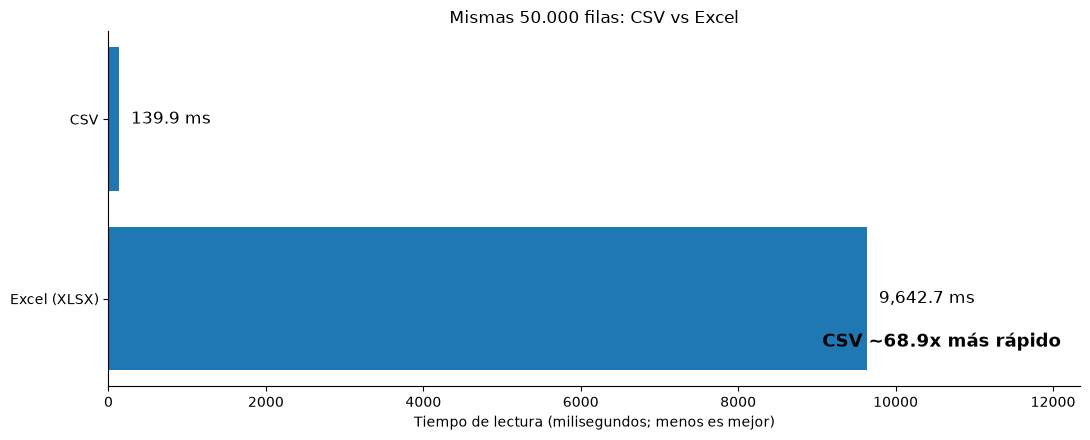

In [4]:
# Gráfico: tiempo real empleado en milisegundos
etiquetas = ["CSV", "Excel (XLSX)"]
tiempos = [csv_ms, xlsx_ms]

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(etiquetas, tiempos)
ax.invert_yaxis()
ax.set_xlim(0, max(tiempos) * 1.28)
ax.set_xlabel("Tiempo de lectura (milisegundos; menos es mejor)")
ax.set_title("Mismas 50.000 filas: CSV vs Excel")
for barra, ms in zip(bars, tiempos):
    ax.text(ms + max(tiempos)*0.015, barra.get_y()+barra.get_height()/2,
            f"{ms:,.1f} ms", va="center", fontsize=12)
ax.text(0.98, 0.10, f"CSV ~{factor:.1f}x más rápido",
        ha="right", va="bottom", transform=ax.transAxes, fontsize=13, weight="bold")
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()


## Qué demuestra y qué no demuestra

- Los datos, columnas y orden de registros son equivalentes en los dos formatos.
- CSV almacena texto plano; XLSX es un paquete ZIP de documentos XML con estructura adicional.
- El tiempo depende del disco, CPU, caché del sistema, versiones de librerías y contenido de los datos.
- CSV no conserva hojas, estilos, gráficos ni fórmulas de Excel.
- En datos tabulares grandes, para lectura repetida en Python también merece la pena explorar **Parquet** (otra práctica).
